## Ticket Classification

### Load dataset

 Hugging Face Dataset - https://huggingface.co/datasets/mteb/banking77

In [1]:
# import libraries

from datasets import load_dataset, DatasetDict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from transformers import pipeline
from transformers import AutoTokenizer
from transformers import TrainingArguments, Trainer
from transformers import AutoModelForSequenceClassification, DistilBertForSequenceClassification, DistilBertModel

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import f1_score

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

In [2]:
# control content display
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

In [3]:
bank_df = load_dataset("mteb/banking77")
bank_df

README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/294k [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/91.4k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/9993 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3076 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 9993
    })
    test: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 3076
    })
})

In [4]:
test_df = bank_df["test"].to_pandas()
train_df = bank_df["train"].to_pandas()

train_df.head()

,text,label,label_text
0,I am still waiting on my card?,11,card_arrival
1,What can I do if my card still hasn't arrived ...,11,card_arrival
2,I have been waiting over a week. Is the card s...,11,card_arrival
3,Can I track my card while it is in the process...,11,card_arrival
4,"How do I know if I will get my card, or if it ...",11,card_arrival


In [5]:
# all the intent categories
label_category = train_df[['label', 'label_text']].drop_duplicates().sort_values('label').reset_index(drop=True)
label_category.head()

,label,label_text
0,0,activate_my_card
1,1,age_limit
2,2,apple_pay_or_google_pay
3,3,atm_support
4,4,automatic_top_up


### Exploratory Analysis

In [6]:
# check duplicate
train_df["text"].duplicated().sum()

np.int64(0)

In [7]:
# data info
train_df["label"].value_counts().describe()

count     77.000000
mean     129.779221
std       32.974321
min       35.000000
25%      111.000000
50%      127.000000
75%      158.000000
max      187.000000
Name: count, dtype: float64

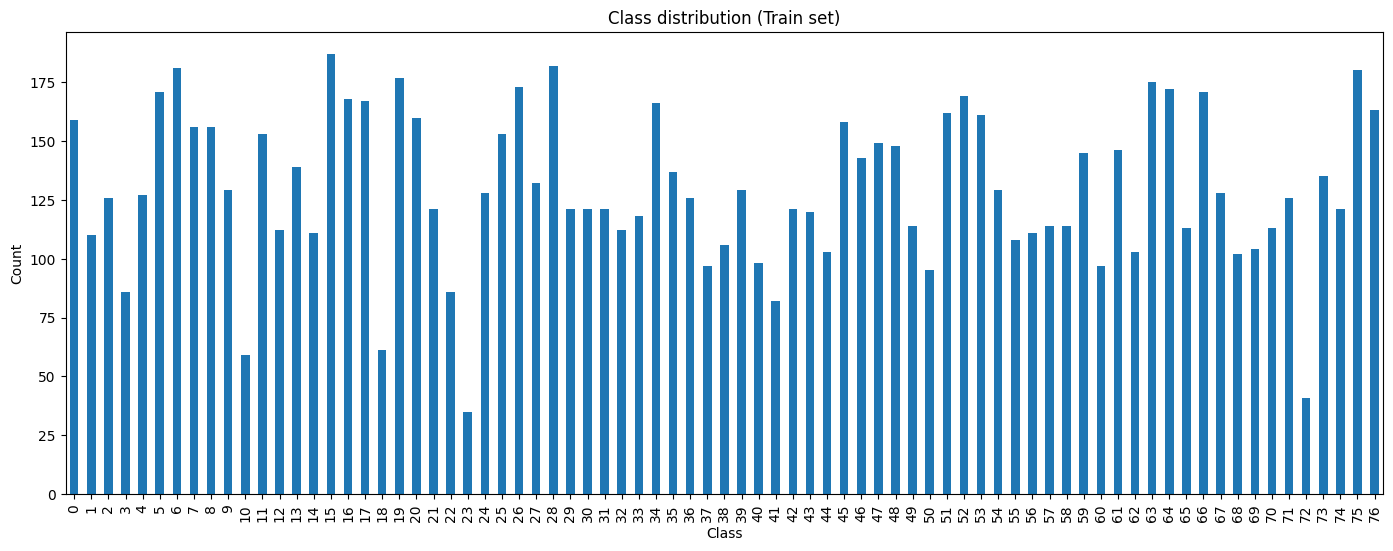

In [8]:
# class distribution
train_df["label"].value_counts().sort_index().plot(kind="bar", figsize=(17,6))
plt.title("Class distribution (Train set)")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

In [9]:
# words check
for label in sorted(train_df["label"].unique())[:5]:
    print(f"\nClass {label}")
    print(train_df[train_df["label"] == label]["text"].sample(5).values)


Class 0
['Can you activate my card pls' 'I need my card activated.'
 'With my new card, how may I activate it?' 'How do i activate my card'
 'What identification is required to activate my card?']

Class 1
['are there age requirements'
 'What does my daughter need to open an account?'
 'How old do kids have to be to open an account?'
 "I'd like to open an account for my children. How can I do that?"
 'I have young kids. Can they use this service?']

Class 2
['Hi, I have an apple watch. How do I use it to top up my card?'
 'Can I use Apple Pay to top-up?' 'Can I top up with Google Pay?'
 "Google Pay won't let me top up."
 'My Apple Pay top up with my American Express card is not working? Please tell me why']

Class 3
['Where can I get money from my card?'
 'Which ATMs accept this circuit board ?'
 'How can I find an ATM that accepts this card?'
 'I need an ATM right now!' 'Can I use this card at any ATM?']

Class 4
['Do I have to manually top-up my account each time or will it do it on

In [10]:
# text length analysis
train_df["text_length"] = train_df["text"].apply(lambda x: len(x.split()))
train_df["text_length"].describe()

count    9993.000000
mean       11.955369
std         7.891187
min         3.000000
25%         7.000000
50%        10.000000
75%        13.000000
max        79.000000
Name: text_length, dtype: float64

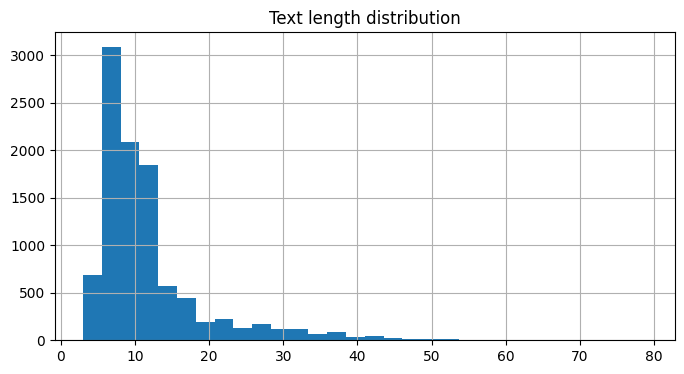

In [11]:
train_df["text_length"].hist(bins=30, figsize=(8,4))
plt.title("Text length distribution")
plt.show()

In [12]:
# to check outliers
train_df.sort_values("text_length", ascending=False).head(10)

,text,label,label_text,text_length
3914,Hearing back from us regarding your important ...,68,unable_to_verify_identity,79
7301,Hi! I'm a university student studying abroad a...,64,transfer_fee_charged,78
3931,Hearing about your verification results from u...,68,unable_to_verify_identity,75
3902,You will hear back from us about your verifica...,68,unable_to_verify_identity,70
3907,It can take between 10 minutes to an hour befo...,68,unable_to_verify_identity,70
5508,Hello-Can you please help me get a refund from...,52,request_refund,69
7220,"I transferred 7,000 to a receiver outside the ...",64,transfer_fee_charged,68
6384,My account shows I have been charged twice for...,63,transaction_charged_twice,66
3634,I think my card is being used by someone else ...,16,card_payment_not_recognised,64
3929,"If you are waiting for verification, it can ta...",68,unable_to_verify_identity,64


In [13]:
# long text : shows the text with more than 40 words in each label
long_texts = train_df[train_df["text_length"] > 40]
print(long_texts["label"].value_counts())

label
63    19
64    19
66    16
46    12
51    11
28     7
35     7
75     6
53     6
68     5
48     5
52     4
19     3
16     3
15     3
25     2
22     2
41     1
6      1
47     1
8      1
42     1
27     1
7      1
59     1
5      1
Name: count, dtype: int64


In [14]:
# words counts
stop_words = " ".join(train_df["text"]).lower().split()
Counter(stop_words).most_common(20)

[('i', 8305),
 ('my', 5682),
 ('to', 4006),
 ('a', 3564),
 ('the', 3496),
 ('is', 2338),
 ('can', 1837),
 ('do', 1729),
 ('card', 1635),
 ('it', 1556),
 ('for', 1534),
 ('how', 1511),
 ('what', 1367),
 ('why', 1233),
 ('and', 1212),
 ('you', 1177),
 ('was', 1089),
 ('have', 975),
 ('not', 953),
 ('in', 944)]

In [15]:
# exclude stop words
filtered_words = [words for words in stop_words if words not in ENGLISH_STOP_WORDS]
Counter(filtered_words).most_common(20)

[('card', 1635),
 ('money', 919),
 ('transfer', 860),
 ('need', 695),
 ('account', 684),
 ('card?', 653),
 ('payment', 644),
 ('cash', 578),
 ('exchange', 504),
 ('charged', 501),
 ('use', 409),
 ('did', 379),
 ('fee', 372),
 ('long', 343),
 ('atm', 338),
 ('new', 334),
 ('account?', 324),
 ("didn't", 308),
 ('does', 303),
 ("don't", 303)]

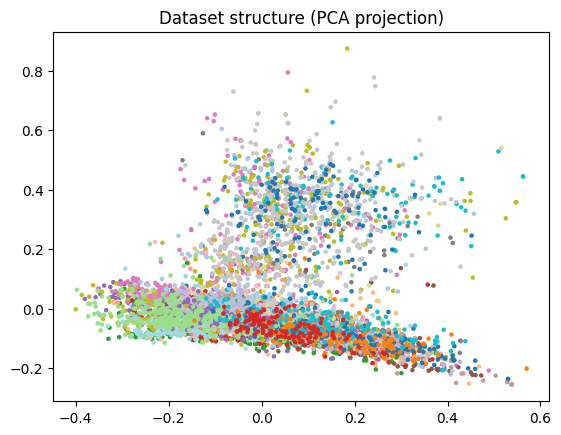

In [16]:
# PCA
vec = TfidfVectorizer(max_features=500)
X = vec.fit_transform(train_df["text"])

X_reduced = PCA(n_components=2).fit_transform(X.toarray())

plt.scatter(X_reduced[:,0], X_reduced[:,1], c=train_df["label"], cmap="tab20", s=5)
plt.title("Dataset structure (PCA projection)")
plt.show()

### Tokenization

In [17]:
# load tokenizer
name = "distilbert/distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(name)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [18]:
# Prepare the dataset - this tokenizes the dataset in batches of 16 examples.
bank_tokenized = bank_df.map(
    lambda example: tokenizer(example['text'], 
                              padding=True, 
                              truncation=True, 
                              max_length=64), 
    batched=True, batch_size=16
)

bank_tokenized = bank_tokenized.remove_columns(["text", "label_text"])
bank_tokenized = bank_tokenized.rename_column("label", "labels")
bank_tokenized.set_format("torch")

Map:   0%|          | 0/9993 [00:00<?, ? examples/s]

Map:   0%|          | 0/3076 [00:00<?, ? examples/s]

In [19]:
bank_tokenized['train'][0:2]

{'labels': tensor([11, 11]),
 'input_ids': tensor([[ 101, 1045, 2572, 2145, 3403, 2006, 2026, 4003, 1029,  102,    0,    0,
             0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0],
         [ 101, 2054, 2064, 1045, 2079, 2065, 2026, 4003, 2145, 8440, 1005, 1056,
          3369, 2044, 1016, 3134, 1029,  102,    0,    0,    0,    0,    0]]),
 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]),
 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
         [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0]])}

### Fine-tune with HuggingFace Trainer

In [20]:
model = DistilBertForSequenceClassification.from_pretrained('distilbert-base-uncased', num_labels=77)

arguments = TrainingArguments(
    output_dir="banking77_trainer",
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=8,
    eval_strategy="epoch", # run validation at the end of each epoch
    save_strategy="epoch",
    weight_decay=0.01,
    learning_rate=2e-5,
    load_best_model_at_end=True,
    seed=224
)


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [21]:
def compute_metrics(eval_pred):
    """Called at the end of validation. Gives accuracy"""
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    
    # calculates the accuracy and f1-score
    acc = np.mean(predictions == labels)
    f1 = f1_score(labels, predictions, average='macro')
    return {"accuracy": acc, "f1_macro": f1}


In [22]:
# split train into train/val

from sklearn.metrics import f1_score
import numpy as np

split = bank_tokenized['train'].train_test_split(test_size=0.1, seed=224)
                                                # stratify_by_column="labels")
train_dataset = split['train']   # 90% of original train
val_dataset = split['test']      # 10% of original train 


trainer = Trainer(
    model=model,
    args=arguments,
    train_dataset=train_dataset,
    eval_dataset=val_dataset, 
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)


In [23]:
# train the model
trainer.train()

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,No log,5.170168,0.578000,0.492658
2,5.943460,2.793259,0.801000,0.737739
3,5.943460,1.651829,0.863000,0.838454
4,2.241164,1.147587,0.889000,0.874304
5,2.241164,0.915831,0.902000,0.888778
6,1.050327,0.815970,0.906000,0.901941
7,1.050327,0.760744,0.906000,0.904460
8,0.646504,0.741478,0.912000,0.908962


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


... (9 outputs left out)

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.weight', 'distilbert.embeddings.LayerNorm.bias'].
There were unexpected keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.beta', 'distilbert.embeddings.LayerNorm.gamma'].


TrainOutput(global_step=2256, training_loss=2.249178920231812, metrics={'train_runtime': 350.6712, 'train_samples_per_second': 205.161, 'train_steps_per_second': 6.433, 'total_flos': 1166663194102062.0, 'train_loss': 2.249178920231812, 'epoch': 8.0})

### Evaluation

In [24]:
test_dataset = bank_tokenized['test']

predictions = trainer.predict(test_dataset)

y_pred = predictions.predictions.argmax(axis=1)
y_true = predictions.label_ids

print(classification_report(y_true, y_pred))

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


              precision    recall  f1-score   support

           0       1.00      0.97      0.99        40
           1       0.95      1.00      0.98        40
           2       1.00      1.00      1.00        40
           3       0.97      0.97      0.97        39
           4       1.00      0.90      0.95        40
           5       0.77      0.75      0.76        40
           6       0.97      0.95      0.96        40
           7       0.93      0.93      0.93        40
           8       1.00      0.93      0.96        40
           9       0.95      0.97      0.96        40
          10       1.00      0.80      0.89        40
          11       0.78      0.88      0.82        40
          12       0.90      0.88      0.89        40
          13       0.91      0.97      0.94        40
          14       0.81      0.95      0.87        40
          15       0.84      0.95      0.89        40
          16       0.86      0.90      0.88        40
          17       0.93    

In [25]:
# checks
train_df[train_df['label'] == 53]  
# why_verify_identity, topping_up_by_card, verify_my_identity, pending_transfer, reverted_card_payment?, 

,text,label,label_text,text_length
6714,I wanted to purchase something online but the ...,53,reverted_card_payment?,32
6715,"I tried to use my debit card, but the payment ...",53,reverted_card_payment?,13
6716,"Hi, I had an issue with my card payment and It...",53,reverted_card_payment?,53
6717,I think my card payment has been reverted,53,reverted_card_payment?,8
6718,Tell me why my card payment would be reverted.,53,reverted_card_payment?,9
6719,Why has my card payment been reversed?,53,reverted_card_payment?,7
6720,I didn't cancel my card payment.,53,reverted_card_payment?,6
6721,Can you tell me why the card payment came back?,53,reverted_card_payment?,10
6722,How come the money from the merchant appeared ...,53,reverted_card_payment?,12
6723,My payment was terminated,53,reverted_card_payment?,4


In [26]:
# top 10 classes
top10_classes = np.argsort(np.bincount(y_true))[-10:]

# filter data
mask = np.isin(y_true, top10_classes)
y_true_10 = np.array(y_true)[mask]
y_pred_10 = np.array(y_pred)[mask]

In [27]:
# remap labels
label_map = {old: i for i, old in enumerate(top10_classes)}

y_true_mapped = np.array([label_map[y] for y in y_true_10])
y_pred_mapped = np.array([label_map.get(y, -1) for y in y_pred_10])

In [28]:
# confusion matrix
cm_10 = confusion_matrix(y_true_mapped, y_pred_mapped)

In [29]:
# normalize - removes nan
cm_10_norm = cm_10.astype(float) / np.maximum(cm_10.sum(axis=1, keepdims=True), 1)

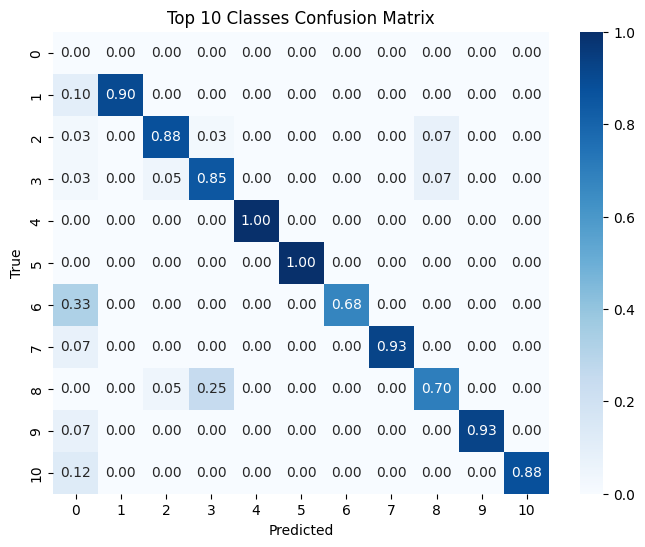

In [30]:
plt.figure(figsize=(8,6))

sns.heatmap(
    cm_10_norm,
    annot=True,
    cmap="Blues",
    fmt=".2f"
)

plt.title("Top 10 Classes Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")

plt.show()

In [31]:
sample_df = test_df
sample_df["actual"] = sample_df["label"]
sample_df["predicted"] = y_pred

In [32]:
label_map = (
    sample_df[["label", "label_text"]]
    .drop_duplicates()
    .set_index("label")["label_text"]
    .to_dict()
)

In [33]:
sample_df["actual_intent"] = sample_df["actual"].map(label_map)
sample_df["predicted_intent"] = sample_df["predicted"].map(label_map)

In [34]:
errors_df = sample_df[
    sample_df["actual"] != sample_df["predicted"]
]

errors_df = errors_df.sample(
    min(10, len(errors_df)),
    random_state=42
)

errors_df[
    [
        "text",
        "actual_intent",
        "predicted_intent"
    ]
]

,text,actual_intent,predicted_intent
1711,I would like to cancel a payment. I purchased ...,request_refund,reverted_card_payment?
2633,how many transactions can i make with a dispos...,get_disposable_virtual_card,disposable_card_limits
2559,Can you look to make sure the exchange rate is...,wrong_exchange_rate_for_cash_withdrawal,card_payment_wrong_exchange_rate
156,How can I check the exchange rate applied to m...,card_payment_wrong_exchange_rate,exchange_rate
960,Can I use my card for payment all over the world?,card_acceptance,country_support
2464,how come i can't find anywhere to load using cash,top_up_by_cash_or_cheque,atm_support
1023,I tryed to make a top-up with cryptocurrency b...,top_up_reverted,beneficiary_not_allowed
1189,what is the identity check?,why_verify_identity,verify_my_identity
66,The app doesn't show the card I received.,card_linking,card_arrival
1772,I bought something and returned it and the mon...,Refund_not_showing_up,reverted_card_payment?


In [35]:
results = trainer.evaluate()
results

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


{'eval_loss': 0.7414777874946594,
 'eval_accuracy': 0.912,
 'eval_f1_macro': 0.9089624688082972,
 'eval_runtime': 1.667,
 'eval_samples_per_second': 599.882,
 'eval_steps_per_second': 19.196,
 'epoch': 8.0}

In [36]:
# predict intent

clf = pipeline(
    "text-classification",
    model=trainer.model,
    tokenizer=tokenizer
)

text = "my account is locked"
pred = clf(text)[0]

pred_id = int(pred["label"].split("_")[1])

print("Text:", text)
print("Prediction:", label_map[pred_id])
print("Confidence:", pred["score"])

Text: my account is locked
Prediction: terminate_account
Confidence: 0.5667740702629089
